# P4 Theory · Transformer와 LLM의 기본 이해

**수업 목표:** 원래 Transformer의 **Encoder–Decoder 아키텍처**를 이해한 후, 사전훈련된 모델을 이용한 **영어→스페인어 번역**과 **Decoder-only 언어 생성**을 연결한다. 마지막으로 두 구조를 결합하는 문서 검색·답변 생성 프로젝트의 기본 아이디어를 이해한다.

**범위:** Transformer와 LLM의 기본 원리를 설명하는 내용. 수학적 유도, 역전파, 직접 모델 훈련, 강화학습은 다루지 않는다.

> 핵심 질문: **입력된 문장은 어떻게 숫자가 되고, Transformer는 이를 어떻게 처리하며, 모델은 어떻게 문장을 출력할까?**

**배경 자료:** Vaswani et al. (2017), *Attention Is All You Need*.


## 전체 학습 흐름

| 학습 주제 | 핵심 질문 | 실습 연결 |
|---|---|---|
| 텍스트 인코딩·Attention | 텍스트를 어떻게 숫자로 바꾸고, 토큰 사이의 관계를 어떻게 파악할까? | 토큰·ID·임베딩 모양 확인, 간단한 Attention |
| 원래 Transformer·번역 | 원래 Transformer의 Encoder와 Decoder는 어떻게 작동할까? | **영어→스페인어** 사전훈련 번역 모델 |
| Decoder-only·LLM | Encoder 없이 Decoder만 사용하면 어떻게 문장을 만들까? | 다음 토큰 확률, 텍스트 이어쓰기와 짧은 질의응답 |

각 주제의 원리를 살펴본 뒤 대응하는 실습으로 확인한다. **P4 Project**에서는 아래에서 소개하는 Encoder-only의 문서 검색과 Decoder-only의 답변 생성을 연결한다. 프로젝트는 사전훈련 모델을 사용하며 모델을 직접 훈련하지 않는다.


---
# 텍스트는 어떻게 Transformer의 입력이 되는가?

Transformer는 글자 자체를 계산하는 것이 아니라 **숫자로 표현된 토큰**을 처리한다. 이 절에서는 아래 **하나의 문장**을 계속 사용한다.

> **공통 문장:** `The unbelievable red car is fast.`

처리 과정은 다음과 같다.

```text
공통 문장
   ↓ ① 텍스트 표준화
표기 방식이 정리된 문장
   ↓ ② 토큰화
토큰의 목록
   ↓ ③ 어휘집에서 토큰 ID 조회
정수 ID 배열
   ↓ ④ 임베딩 테이블에서 벡터 조회
토큰마다 256개의 실수
   ↓ ⑤ 위치 정보 추가
Transformer에 전달할 벡터들
```

수업에서는 **단어 기준 토큰 7개**, **교육용 토큰 ID 10~16**, **어휘집 크기 10,000**, **토큰 표현 차원 256**을 일관되게 사용한다. 이 숫자들은 **구조를 설명하기 위한 설정**이며, 뒤에서 사용하는 실제 번역 모델은 자체 토크나이저와 가중치를 가진다.

## 텍스트 표준화란?

**텍스트 표준화**(Text Standardization)는 같은 내용의 텍스트가 서로 다른 표기 방식으로 들어오더라도 **미리 정한 규칙에 따라 일관된 형태로 정리하는 과정**이다. 모델이 텍스트를 토큰화하기 전에 이루어질 수 있으며, 처리 방식은 모델이나 과제에 따라 다르다.

우리의 문장이 복사·입력 과정에서 다음처럼 들어왔다고 하자. **내용은 같은 문장**이지만 앞뒤에 공백이 있고, 단어 사이 공백 수도 일정하지 않다.

```text
정리 전: "  The   unbelievable  red car is fast.  "
정리 후: "The unbelievable red car is fast."
```

이번 예제의 표준화 규칙은 딱 두 가지다.

1. 문장의 앞뒤에 불필요하게 붙은 공백을 제거한다.
2. 단어 사이에 연속으로 들어간 공백을 하나의 공백으로 통일한다.

```python
import re
raw_text = "  The   unbelievable  red car is fast.  "
text = re.sub(r"\s+", " ", raw_text.strip())
print(text)  # The unbelievable red car is fast.
```

다른 표준화 규칙도 있다. 예컨대 **소문자화**를 적용한다면 같은 문장은 `the unbelievable red car is fast.`가 되고, **문장부호 제거**를 적용한다면 마침표가 사라질 수 있다. 하지만 이 수업에서는 **대문자 `The`와 마침표 `.`를 그대로 유지한다.** 그래야 다음 단계의 토큰 및 ID를 처음부터 끝까지 동일하게 유지할 수 있다.

중요한 것은 **모든 Transformer에 통용되는 하나의 표준화 규칙은 없다는 사실**이다. 어떤 모델은 대소문자 구분을 유지하고, 어떤 모델은 소문자화하며, 최신 토크나이저 중에는 원문 공백을 특별한 기호로 표현하는 것도 있다. **사전훈련된 모델을 사용할 때는 임의의 표준화를 덧씌우지 않고 해당 모델에 저장된 토크나이저를 사용**하는 것이 원칙이다.

## 토큰화: 같은 문장을 어떤 단위로 나눌까?

**토큰화**(Tokenization)는 표준화된 텍스트를 모델이 처리할 **토큰**(Token)이라는 단위로 나누는 과정이다. 토큰은 단어일 수도 있고, 단어의 일부나 문장부호일 수도 있다.

같은 문장 `The unbelievable red car is fast.`를 두 방식으로 나누어 보자.

| 구분 | 나눈 결과 | 토큰 수 |
|---|---|---:|
| **단어 기준**(word-level, 수업용) | `The` / `unbelievable` / `red` / `car` / `is` / `fast` / `.` | **7** |
| **부분단어 기준**(subword-level, 설명용) | `The` / `un` / `believ` / `able` / `red` / `car` / `is` / `fast` / `.` | **9** |

**부분단어**(Subword)는 하나의 단어보다 작은 토큰 조각을 뜻한다. 강의에서는 **'부분단어 토큰화' 또는 '서브워드 토큰화'**라고 부르는 것이 적절하다. 부분단어가 반드시 언어학적인 형태소와 정확히 일치하는 것은 아니다.

왜 부분단어를 사용할까? 어휘집에 없는 긴 단어도 이미 알고 있는 여러 조각으로 표현하기 쉬워지기 때문이다. 다만 위의 `un` / `believ` / `able` 분할은 **개념을 보여주기 위해 가정한 예시**다. 실제 모델이 이렇게 나누는지는 그 모델의 토크나이저에 달려 있다.

**이후 ID·임베딩 예제에는 첫 번째 줄의 단어 기준 7개 토큰만 사용한다.** 두 번째 방식의 9개 토큰은 **서로 다른 토큰화 방식의 비교**이므로 그 9개에 7개짜리 ID를 그대로 적용할 수 없다.

## 어휘집과 토큰 ID란?

**어휘집**(Vocabulary)은 토크나이저가 구별하여 사용할 수 있는 **토큰 종류의 목록**이다. 각 토큰 종류에는 고유한 정수 번호인 **토큰 ID**(Token ID)가 연결된다. 어휘집에 단어만 들어 있는 것은 아니다. 부분단어·문장부호·특수 토큰도 포함될 수 있다.

예를 들어 **어휘집 크기가 10,000개**라는 말은 그 모델이 구분하는 **토큰 종류의 수가 10,000개**라는 뜻이다. **하나의 문장이 10,000개 토큰으로 이루어진다는 뜻은 아니다.** 이 수업에서는 ID `0`부터 `9999`까지 사용할 수 있다고 가정한다.

전체 어휘집 10,000개를 적을 필요는 없다. 다음은 그중 우리 문장에 필요한 **일부 항목**이다.

| 토큰 | `[PAD]` | `[UNK]` | `The` | `unbelievable` | `red` | `car` | `is` | `fast` | `.` |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **수업용 ID** | 0 | 1 | **10** | **11** | **12** | **13** | **14** | **15** | **16** |

- `[PAD]`: 여러 입력의 길이를 맞추기 위해 사용할 수 있는 특수 토큰
- `[UNK]`: 수업용 단어 어휘집에 없는 토큰을 나타내는 특수 토큰

```text
문장:    The unbelievable red car is fast.
토큰:   [The, unbelievable, red, car, is, fast, .]
토큰 ID: [ 10,           11,  12,  13, 14,   15, 16]
```

**ID는 의미나 크기를 나타내는 숫자가 아니다.** `red=12`, `car=13`이라고 해서 두 토큰의 의미가 가깝거나 `car`가 더 큰 값을 갖는 것은 아니다. ID는 어휘집에서 대응하는 토큰을 찾는 **식별 번호**다.

각 모델의 어휘집과 ID 배정은 그 모델의 토크나이저에 고정되어 있다. **새 문장이 입력된다고 해서 매번 어휘집을 다시 만들거나 ID를 새로 매기지 않는다.**

## 토큰 ID를 왜 임베딩 벡터로 바꿀까?

토큰 ID는 정수 번호일 뿐이므로, ID 자체를 단어의 의미로 계산할 수는 없다. Transformer는 각 토큰을 여러 실수로 구성된 **임베딩 벡터**(Embedding Vector)로 나타내어 신경망 연산에 사용한다.

이 수업에서는 **토큰 하나를 256개의 실수로 표현**하는 예제를 사용한다. 256은 토큰 종류의 수가 아니라 **토큰 하나를 표현하는 숫자의 개수**다.

### 어휘집 10,000개라면 임베딩 테이블은?

**임베딩 테이블**(Embedding Table)은 어휘집의 **각 ID에 하나의 벡터를 대응시킨 큰 숫자 표**다.

| 구성 | 행 | 열 | 배열 모양 |
|---|---:|---:|---|
| **전체 임베딩 테이블** | 토큰 종류 10,000개 | 토큰당 실수 256개 | `(10,000, 256)` |
| **우리 문장에서 조회할 행** | ID `10, 11, 12, 13, 14, 15, 16` | 토큰당 256개 | `(7, 256)` |

```text
어휘집의 ID 0~9999  →  임베딩 테이블 E (10,000행 × 256열)
                         ...
                  E[10]  →  The의 256차원 벡터
                  E[11]  →  unbelievable의 256차원 벡터
                  E[12]  →  red의 256차원 벡터
                  E[13]  →  car의 256차원 벡터
                  E[14]  →  is의 256차원 벡터
                  E[15]  →  fast의 256차원 벡터
                  E[16]  →  .의 256차원 벡터
                         ↓
                 문장 표현: 7행 × 256열
```

따라서 **전체 10,000행을 문장마다 복사하는 것이 아니라, 입력된 토큰 ID에 해당하는 행만 조회한다.** 만일 `car`가 문장에 두 번 나온다면, 학습된 모델의 가중치가 고정되어 있는 동안 두 위치 모두 같은 `E[13]`을 가져온다.

임베딩의 256개 좌표가 각각 '성별', '색깔', '속도'처럼 사람이 정해 놓은 의미를 갖는 것은 아니다. 학습된 모델에서는 여러 좌표에 분산된 **숫자 패턴 전체**가 언어 처리에 유용하게 작동한다.

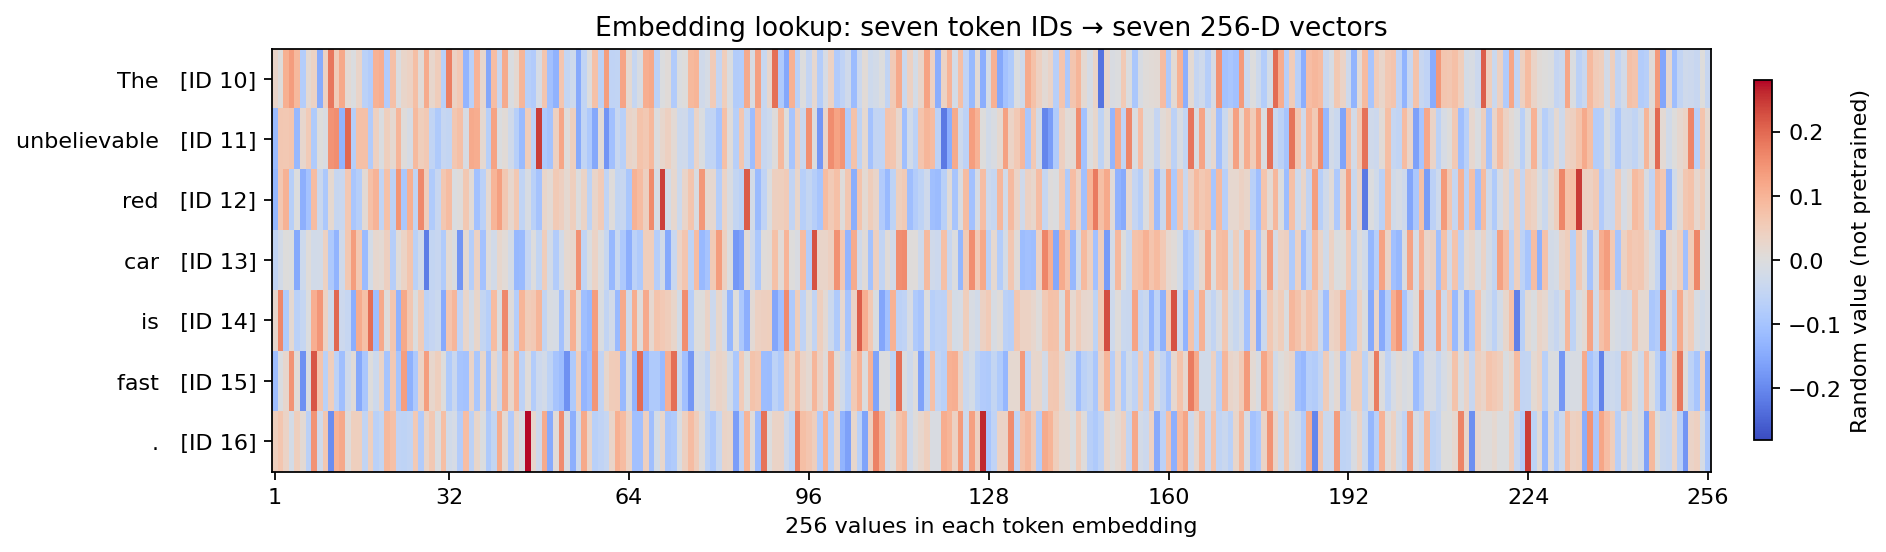

*각 행은 어휘집에서 조회한 토큰 하나의 256개 실수를 나타낸다. 이 그림의 숫자는 **구조 설명을 위해 생성한 초기값**이며, 사전훈련으로 의미를 학습한 실제 모델 가중치가 아니다.*

## 임베딩 테이블의 숫자는 어디서 올까? — 학습과 사전훈련

이제 중요한 질문이 남는다. **임베딩 테이블의 256개 숫자를 누가 정하는가?** 사람이 단어마다 적어 주는 것이 아니다. 임베딩 테이블은 모델의 **학습 가능한 가중치**(Weights) 중 하나다.

**가중치**란 모델이 계산에 사용하는 숫자들이다. 임베딩 테이블뿐 아니라 뒤에서 배우는 Attention의 Q·K·V 변환에도 가중치가 있다.

### 모델을 처음 만들 때와 훈련이 끝났을 때를 구분하자

| 단계 | 임베딩 테이블의 상태 | 의미 |
|---|---|---|
| **① 모델 초기화** | 보통 작은 무작위 숫자로 시작 | 아직 언어를 학습하지 않은 상태 |
| **② 모델 학습** | 수많은 예제를 처리하면서 임베딩과 Attention 등의 가중치를 조정 | 유용한 언어적 패턴이 학습됨 |
| **③ 학습된 모델 저장** | 학습이 끝난 숫자들을 파일로 저장 | 다른 사람이 재사용할 수 있음 |
| **④ 사전훈련된 모델 불러오기** | 저장된 숫자를 그대로 읽음 | **이번 실습은 여기서 시작** |

예를 들어 텍스트 `The unbelievable red car is fast.`가 학습 자료에 포함되어 있다면, 생성형 언어 모델은 앞의 토큰들을 보고 다음 토큰을 예측하는 식으로 학습할 수 있다. 예측이 실제 다음 토큰과 다르면 오차를 줄이도록 가중치가 조정된다. 이 과정이 수많은 문장에 반복되면서 임베딩 값도 달라진다. **이번 수업에서는 그런 훈련 과정을 직접 실행하지 않는다.**

### '사전훈련'과 '사전훈련된 모델'은 무슨 뜻일까?

- **사전훈련**(Pretraining): 일반적으로 대규모 데이터에서 언어 등의 기본 패턴을 **후속 과제에 특화된 추가 학습보다 먼저** 익히는 단계다. 예를 들어 많은 텍스트로 다음 토큰을 예측하며 학습할 수 있다.
- **사전훈련된 모델**(Pretrained Model): 이미 학습되어 **가중치가 저장되어 있는 모델**을 가리키는 표현으로 널리 쓰인다. 이 모델을 다운로드하면 임베딩뿐 아니라 신경망의 다른 가중치도 함께 가져온다.

**주의:** 대규모 텍스트로 일반 사전훈련한 생성형 LLM과, **번역을 수행하도록 이미 훈련된 Encoder–Decoder 번역 모델**은 학습 목적이 동일하지 않다. 다만 이번 실습에서는 어느 쪽이든 **이미 학습된 가중치를 불러와 새로운 입력에 사용하는 것**이 공통점이다.

### 수업의 그림과 실제 모델을 구분하자

**앞의 `(10,000, 256)` 그림은 숫자를 무작위로 만든 교육용 예시**다. 그 표가 언어를 학습한 것은 아니다. 실제 학습된 임베딩을 확인할 때는 뒤의 Lab에서 **번역 모델에 저장된 임베딩 테이블을 따로 불러와 조회**한다. 실제 모델의 어휘집 크기와 임베딩 차원은 수업용 숫자와 달라도 정상이다.

## 같은 ID와 같은 임베딩, 그런데 문맥에 따라 표현이 달라지는 이유

이 설명은 **임베딩 테이블을 조회하는 단계**와 **Transformer가 문맥을 처리하는 단계**를 구분하기 위해 필요하다.

- 현재 수업의 어휘집에서 `car`는 언제나 **ID 13**이다.
- 같은 모델에서 가중치를 바꾸지 않는 한 `E[13]`은 언제나 **같은 256차원 토큰 임베딩**이다.
- 하지만 그 벡터가 **문장의 어느 위치에 놓였는지**, 또 **주변에 어떤 토큰이 있는지**에 따라 나중에 만들어지는 **문맥을 반영한 표현**은 달라질 수 있다.

즉, `E[13]`은 임베딩 테이블에서 꺼낸 **출발점**이다. 뒤에서 배울 **위치 인코딩과 Self-Attention**을 거치면 최종 표현은 달라질 수 있다. 따라서 **'토큰 임베딩'과 'Attention을 통과한 문맥 표현'은 같은 것이 아니다.**

## 새로운 문장이 들어오면 길이를 미리 정해야 할까?

**문장 길이를 모두 미리 알아둘 필요는 없다.** 텍스트가 입력되면 토크나이저로 나눈 뒤, 그때 얻어진 **토큰 수만큼 임베딩 행을 조회**한다. 어휘집 크기와 임베딩 차원은 그대로 유지된다.

같은 공통 문장과 그 문장의 앞부분을 비교해 보자.

| 입력 | 단어 기준 토큰 수 | 토큰 ID 배열 | 조회 후 모양 |
|---|---:|---|---|
| `The unbelievable red car is fast.` | 7개 | `[10,11,12,13,14,15,16]` | `(7,256)` |
| 위 문장의 앞부분 `The unbelievable red car` | 4개 | `[10,11,12,13]` | `(4,256)` |

**최대 입력 길이**와 **실제 문장 길이**도 구분해야 한다. 모델이 한 번에 처리하도록 설계된 **최대 토큰 수**가 있다고 해서, 그보다 짧은 문장에 반드시 최대 길이까지 패딩을 붙이는 것은 아니다.

예를 들어 **최대 길이가 512토큰인 가상의 모델**에 7개 토큰을 하나만 입력할 때는 일반적으로 **7개 길이 그대로 처리할 수 있다.** 여기서 `512`는 **모델의 허용 상한**을 설명하기 위한 숫자이며, 아래의 배치 길이와는 별개다. 너무 긴 입력은 모델의 한도에 맞춰 나누거나 잘라야 할 수 있다.

## 패딩은 언제 필요할까? — 문장 길이와 미니배치

모델은 여러 입력을 한꺼번에 계산하기도 한다. 이때 길이가 다른 문장을 **하나의 직사각형 배열**(텐서)로 묶기 위해 짧은 쪽에 **패딩**(Padding)을 붙일 수 있다. 하지만 패딩은 **항상 필수인 것은 아니다.** 한 문장만 처리하거나, 가변 길이를 지원하는 계산 방법을 쓰면 불필요할 수 있다.

공통 문장 전체와 그 문장의 앞부분을 **같은 배치에 넣는 경우**를 보자.

```text
입력 A — 7개 : [10, 11, 12, 13, 14, 15, 16]
입력 B — 4개 : [10, 11, 12, 13]

배치 계산을 위해 길이를 7로 맞춤:
입력 A       : [10, 11, 12, 13, 14, 15, 16]
입력 B       : [10, 11, 12, 13,  0,  0,  0]
                                          ↑ [PAD]는 실제 단어가 아님
```

이 예시에서 **배치에 맞춘 길이 7**은 모델의 **최대 입력 길이**와 아무 관계가 없다. 다른 배치를 묶으면 필요한 패딩 길이는 달라질 수 있지만, **모델 자체의 최대 길이가 바뀌는 것은 아니다.** 배치에서 가장 긴 입력에 길이를 맞추는 방식을 **동적 패딩**(Dynamic Padding)이라 한다.

### 패딩 자리도 단어처럼 참고하면 안 되지 않을까?

바로 이 때문에 **패딩용 Attention Mask**(Padding Attention Mask)가 등장한다. Attention의 자세한 계산은 다음 절에서 배우지만, 여기서는 **실제 토큰을 참고해도 되는지 표시하는 배열**이라고 이해하자.

```text
입력 A의 마스크: [1, 1, 1, 1, 1, 1, 1]
입력 B의 마스크: [1, 1, 1, 1, 0, 0, 0]
                             ↑ 0: 패딩 위치이므로 참고에서 제외
```

이렇게 **패딩은 길이를 맞추고**, **마스크는 계산에서 패딩 위치를 구별**하도록 한다. 보통 함께 쓸 수 있지만 항상 필요한 것은 아니다. **마스크에서 1과 0이 뜻하는 내용은 라이브러리에 따라 다를 수 있으므로** 실제 코드에서는 사용 모델의 규칙을 확인해야 한다.

이때 배치의 ID 배열은 `(2,7)`, 임베딩은 `(2,7,256)`이 된다. 세 차원은 차례대로 **입력 수 2개, 이번 배치에서 맞춘 길이 7, 토큰 표현 차원 256**이다. 나중에 배우는 **Causal Mask**는 미래 출력 토큰을 가리는 것으로, **패딩 마스크와 목적이 다르다.**

## 위치 인코딩: 토큰의 종류만으로는 순서를 알 수 없다

이제 7개 토큰의 임베딩 벡터를 준비했다. 그런데 임베딩 테이블은 **무슨 토큰인가**는 알려 주어도, **문장 안의 몇 번째 위치에 놓였는가**를 자동으로 알려 주지는 않는다. 원래 Transformer는 이를 위해 **위치 인코딩**(Positional Encoding)을 사용했다.

### 문장 안의 토큰에 위치 번호 붙이기

| 위치 번호 | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| 토큰 | `The` | `unbelievable` | `red` | `car` | `is` | `fast` | `.` |
| 토큰 ID | 10 | 11 | 12 | 13 | 14 | 15 | 16 |

### 위치마다 다른 256차원 벡터 만들기

원래 Transformer에서는 위치 번호가 $p$일 때, **사인·코사인 함수**를 이용해 위치 벡터 $P[p]$를 만들었다. 여러 차원에 **서로 다른 주기의 사인·코사인 값**을 배치하므로 같은 256차원 공간에서도 위치별 패턴이 달라진다.

처음 두 좌표는 다음처럼 생각할 수 있다.

| 위치 $p$ | 첫 번째 값 $\sin(p)$ | 두 번째 값 $\cos(p)$ |
|---:|---:|---:|
| 0 | 0.000 | 1.000 |
| 1 | 0.841 | 0.540 |
| 2 | 0.909 | -0.416 |
| 3 | 0.141 | -0.990 |

이것은 **256차원 중 앞 두 좌표만 보여준 것**이다. 나머지 좌표에는 다른 주기의 숫자가 들어간다. 따라서 `P[0]`, `P[1]`, `P[2]`, … 는 **서로 다른 256차원 위치 벡터**가 된다.

### 같은 위치에 있는 두 벡터를 원소별로 더하기

원래 Transformer에서 **모델의 토큰 표현 차원**을 $d_{\mathrm{model}}$이라 부른다. 이 수업에서는 $d_{\mathrm{model}}=256$으로 설정했다. 토큰 임베딩과 위치 벡터를 **같은 256개 자리끼리** 더해야 하므로 두 벡터의 길이도 256으로 맞춘 것이다.

```text
위치 0: The           → E[10] + P[0] → 길이 256인 입력 벡터
위치 1: unbelievable  → E[11] + P[1] → 길이 256인 입력 벡터
위치 2: red           → E[12] + P[2] → 길이 256인 입력 벡터
위치 3: car           → E[13] + P[3] → 길이 256인 입력 벡터
위치 4: is            → E[14] + P[4] → 길이 256인 입력 벡터
위치 5: fast          → E[15] + P[5] → 길이 256인 입력 벡터
위치 6: .             → E[16] + P[6] → 길이 256인 입력 벡터
```

가령 `car`에서 **첫 번째 좌표**는 `E[13]`의 첫 번째 숫자와 `P[3]`의 첫 번째 숫자를 더한 값이다. 이를 256개 좌표 모두에 적용한다. **벡터를 이어 붙여 512차원으로 만드는 것이 아니라, 같은 위치의 두 숫자를 더해 256차원을 유지하는 것이다.**

원래 논문의 입력 계산은 정확하게는 다음과 같이 임베딩 크기를 먼저 조정한다.

$$
\mathbf{x}_{p}=\sqrt{d_{\mathrm{model}}}\,E[\mathrm{ID}_{p}]+P[p]
$$

여기서 $p=0,\ldots,6$이고 $d_{\mathrm{model}}=256$이다. 수식의 핵심은 **'한 토큰의 임베딩 벡터 + 그 토큰 위치의 벡터'**이다.

| 배열 | 크기 | 역할 |
|---|---|---|
| 7개 토큰 임베딩 | `(7, 256)` | 토큰 종류에 관한 256개 값 |
| 7개 위치 벡터 | `(7, 256)` | 토큰 위치에 관한 256개 값 |
| **원소별 덧셈 결과** | **`(7, 256)`** | Transformer에 전달할 벡터 |

여기서 `(7, 256)`은 **배열의 모양**이다. 숫자 `7`과 `256`을 더하는 식이 아니다.

### 위치 벡터는 문장이 달라져도 같은가?

**원래 Transformer의 사인·코사인 절대 위치 인코딩이라면 그렇다.** 같은 모델 설정에서 **0번 위치에 놓인 토큰에는 텍스트가 무엇이든 같은 `P[0]`**, 1번 위치에는 같은 `P[1]`이 더해진다. 토큰의 종류에 따라 **토큰 임베딩 `E[ID]`가 달라지고**, 위치에 따라 **위치 벡터 `P[p]`가 달라지는 것**이다.

다만 **모든 현대 Transformer가 이 방식을 사용하는 것은 아니다.** 학습되는 위치 임베딩이나 상대 위치 정보를 사용하는 모델도 있다. 문장 시작의 특수 토큰, 패딩 방향, 프롬프트 앞부분에 붙는 토큰 등에 따라 **실제 단어가 받는 위치 번호도 달라질 수 있다.** 이번 절에서는 원래 Transformer의 절대 위치 방식을 이해하는 데 집중한다.

### 텍스트 인코딩 정리 — 같은 문장의 처리 과정을 연결해 보기

```text
"  The   unbelievable  red car is fast.  "  ← 공백이 일정하지 않은 입력
                ↓ 표준화
The unbelievable red car is fast.
                ↓ 단어 기준 토큰화 (수업용 규칙)
[The, unbelievable, red, car, is, fast, .]         7개
                ↓ 고정된 수업용 어휘집에서 ID 조회
[10, 11, 12, 13, 14, 15, 16]                      (7,)
                ↓ 전체 임베딩 테이블 E(10,000×256)에서 7개 행 조회
각 토큰의 임베딩                                   (7,256)
                ↓ 위치 0~6의 벡터를 같은 자리끼리 더함
Transformer 입력 표현                            (7,256)
```

- **어휘집 크기 10,000**은 토큰의 종류 수이고, **문장 길이 7**은 이번 입력의 토큰 수다.
- **임베딩 테이블**은 학습 과정에서 바뀔 수 있는 가중치다. 수업용 임의 숫자와 실제 사전훈련된 모델의 저장된 숫자를 혼동하지 않는다.
- **입력 길이, 배치의 패딩 길이, 모델의 최대 허용 길이**는 서로 다른 개념이다.
- 원래 Transformer의 **사인·코사인 위치 벡터**는 같은 위치 번호라면 문장 내용과 무관하게 동일한 규칙으로 계산된다.

**확인 질문:** (1) 같은 문장을 단어 기준과 부분단어 기준으로 나누면 토큰 수가 달라지는 이유는 무엇인가? (2) `(10,000,256)`에서 `(7,256)`이 만들어지는 과정을 설명해 보자. (3) 토큰 임베딩이 무작위인 경우와 사전훈련된 경우의 차이는 무엇인가? (4) 문장 길이가 7인데 모델의 최대 허용 길이가 512라면 항상 512로 패딩해야 하는가? (5) 왜 `car`에는 `E[13]`과 `P[3]`을 함께 사용할까?

---
# 단어 사이의 관계를 어떻게 파악하는가? — Self-Attention과 Q·K·V

앞에서 `The unbelievable red car is fast.`를 **7개 토큰**, 각 **256차원 벡터**로 나타냈다. 이제 이 토큰들이 **서로 정보를 참고해 문맥에 맞는 표현으로 바뀌는 과정**을 살펴보자.

예를 들어 `car`라는 토큰의 표현을 만들 때 `red`(색깔)와 `fast`(자동차의 속도에 관한 서술) 같은 주변 토큰 정보가 도움이 될 수 있다. Self-Attention은 **어떤 토큰을 얼마만큼 참고할지 계산해 다른 토큰의 정보를 섞는 방법**이다.


## Q·K·V는 각 토큰의 역할이 아니라 '정보를 계산하는 세 벡터'다

| 구분 | 역할 | 직관적인 질문 |
|---|---|---|
| **Q**(Query) | 현재 토큰이 찾는 정보의 조건 | `car`를 표현하려면 어떤 정보를 참고하면 될까? |
| **K**(Key) | 각 토큰이 제공하는 정보의 비교용 표지 | `red`, `fast` 등이 `car`의 요구와 얼마나 관련될까? |
| **V**(Value) | 실제로 가중합하여 가져올 정보 | 참고할 토큰의 정보 중 얼마나 반영할까? |

Q·K·V는 '단어를 셋으로 나눈다'는 뜻이 아니다. **모든 토큰 표현에서 Q·K·V를 각각 계산**한다. 실제 Transformer는 학습된 세 종류의 변환 행렬을 사용한다.

1. 현재 토큰의 Q를 다른 토큰들의 K와 비교하여 **관련성 점수**를 얻는다.
2. 점수를 **Softmax**로 변환하여 합이 1인 **Attention 가중치**를 얻는다.
3. 각 토큰의 V에 가중치를 곱해 더한다. 이것이 **현재 토큰에 반영될 문맥 정보**가 된다.

아래의 숫자는 원리 확인용으로 **인위적으로 설계한 값**이다. 실제 사전훈련 모델의 Attention을 추출한 결과가 아니다.


## 같은 문장의 7개 토큰에 Attention을 적용하면

수업용 ID `[10, 11, 12, 13, 14, 15, 16]`에 대응하는 벡터를 `(7, 256)`으로 준비했다고 하자. 여기서는 `car`(네 번째 토큰)가 `red`와 `fast`에 더 큰 가중치를 주도록 예제 Q·K를 설정한다.

| `car`가 참고하는 토큰 | The | unbelievable | red | car | is | fast | . |
|---|---:|---:|---:|---:|---:|---:|---:|
| **Attention 가중치**(교육용) | 0.047 | 0.047 | **0.344** | 0.126 | 0.047 | **0.344** | 0.047 |

표의 값은 반올림했으므로 합이 1과 약간 다르게 보일 수 있다. 원래 계산에서는 **정확히 1**이다.

`car`의 새 정보는 `red`와 `fast`의 **V 벡터**에 큰 비중을 주고, 나머지 토큰의 V도 해당 가중치만큼 섞어 얻는다. **어떤 토큰을 더 참고할지**가 중요하며 학생이 256개 숫자를 일일이 계산할 필요는 없다.


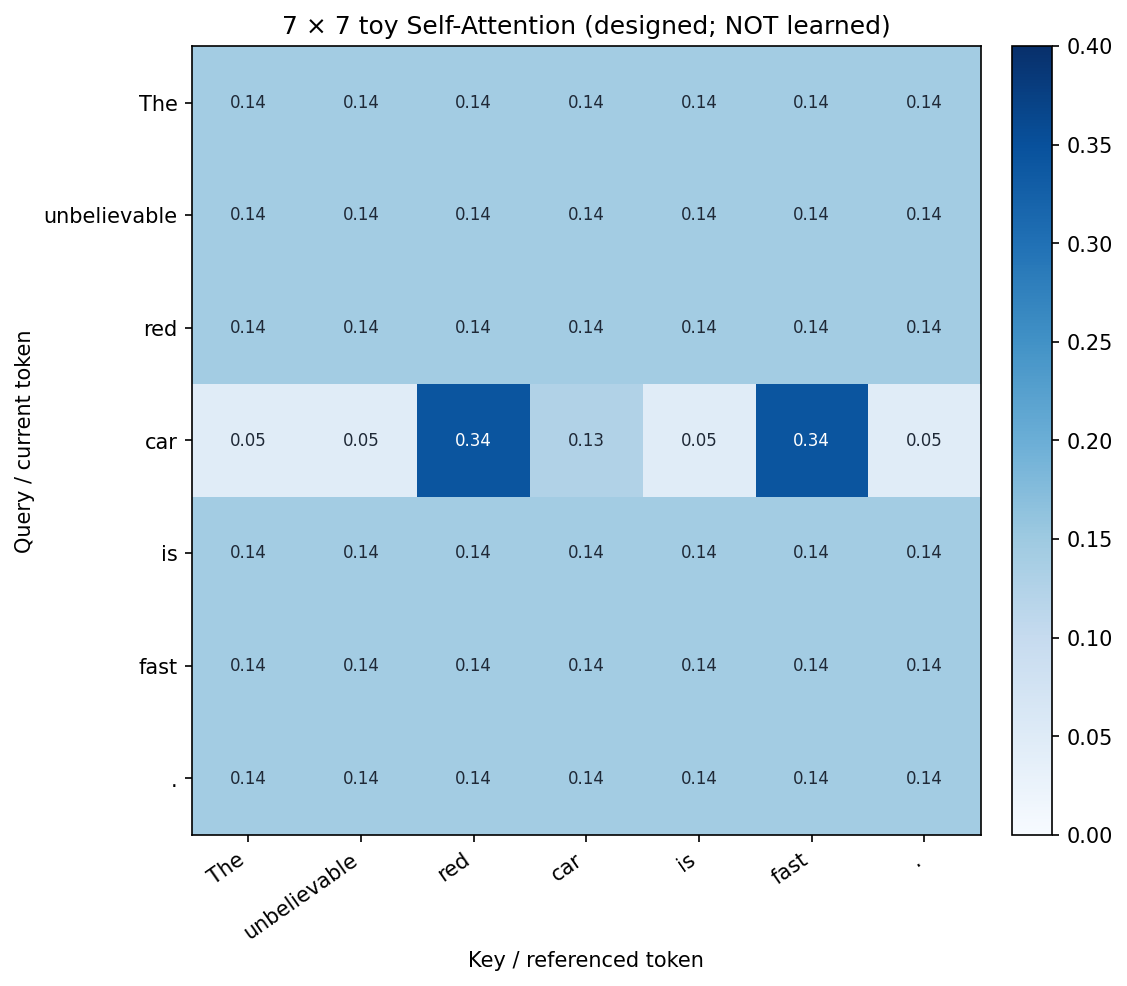

*그림: 행은 현재 토큰(Query), 열은 참고하는 토큰(Key)이다. `car` 행에서 `red`와 `fast`의 가중치가 높게 보이도록 **교육용 Q·K 값을 설정**했다. 다른 토큰 관계를 학습한 실제 모델 결과는 아니다.*


## 왜 Attention 표는 7×7인데 결과는 7×256일까?

| 단계 | 배열 모양 | 의미 |
|---|---|---|
| 입력 X | `(7, 256)` | 7개 토큰의 256차원 표현 |
| Q, K, V | 각각 `(7, 256)` | 하나의 Head를 단순화한 설정 |
| Q와 K의 관련성 점수 | `(7, 7)` | **7개 토큰 각각이 나머지 7개를 얼마나 참고할지** |
| Softmax 가중치 | `(7, 7)` | 행별 가중치 합이 1 |
| 가중치 × V | `(7, 256)` | 각 토큰에 문맥 정보가 반영된 256차원 표현 |

Attention은 임베딩 차원을 7차원으로 줄이는 작업이 아니다. **7×7 가중치 표로 어떤 토큰의 정보를 얼마나 반영할지 결정**하고, 그 결과를 **256차원 벡터들에 적용**하는 과정이다.

원리를 한 줄로 쓰면 다음과 같다.

$$
\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}}\right)V
$$

이 수식의 의미는 **Q·K로 가중치를 정하고 V를 가중합한다**는 것이다. 자세한 행렬 계산은 이번 수업에서 요구하지 않는다.


## Multi-Head Attention은 왜 사용할까?

단일 Head가 관계를 한 가지 방식으로 계산한다면, 여러 Head는 **서로 다른 변환을 사용해 다양한 관계를 함께 계산**할 수 있다.

예를 들어 **토큰 표현 차원 256, Head 4개, Head당 차원 64**로 설계할 수 있다.

```text
입력 토큰 표현: 7 × 256
    ├─ Head 1 : 7 × 64 ─┐
    ├─ Head 2 : 7 × 64 ─┤
    ├─ Head 3 : 7 × 64 ─┼→ 이어 붙이기 → 7 × 256 → 출력 변환
    └─ Head 4 : 7 × 64 ─┘
```

다만 **모든 모델에서 Head 크기가 반드시 64인 것은 아니다.** 또한 특정 Head가 무조건 '색깔'이나 '문법'만 담당한다고 단정할 수 없다. 원래 Transformer 블록에는 Attention 외에도 **Feed Forward 층, 잔차 연결, 정규화** 등이 포함된다.


## Encoder와 Decoder가 사용하는 Attention은 어떻게 다를까?

| 종류 | Q의 출처 | K·V의 출처 | 참고 범위 |
|---|---|---|---|
| **Encoder Self-Attention** | 입력 토큰 | 같은 입력 토큰 | 앞뒤의 입력 토큰 모두 |
| **Decoder Masked Self-Attention** | Decoder의 현재 표현 | 이전 출력 표현 | 현재까지의 출력 토큰만 |
| **Cross-Attention** | Decoder 표현 | Encoder 출력 | 입력 문장의 정보를 참고 |

**Causal Mask**는 Decoder가 *미래에 생성될 출력 토큰*을 미리 참조하지 못하게 한다. 앞에서 본 **Padding Mask**(패딩 자리 제외)와는 목적이 다르다. 다음 장에서 영어 Encoder가 정보를 제공하고 스페인어 Decoder가 새 문장을 생성하는 방법을 연결한다.

**Attention 핵심 요약:** **Q·K는 어디를 참고할지 정하고, V는 실제로 가져올 정보**다. 7개 토큰의 Attention 가중치 표는 `(7, 7)`이지만, 출력된 표현은 `(7, 256)`이다.


---
# 원래 Transformer 아키텍처: Encoder + Decoder

2017년 *Attention Is All You Need*에서 제안한 Transformer는 **Encoder와 Decoder를 함께 사용**하는 구조였다. 입력 언어의 문장을 받아 다른 언어의 문장을 생성하는 기계 번역을 생각하면 이해하기 쉽다.

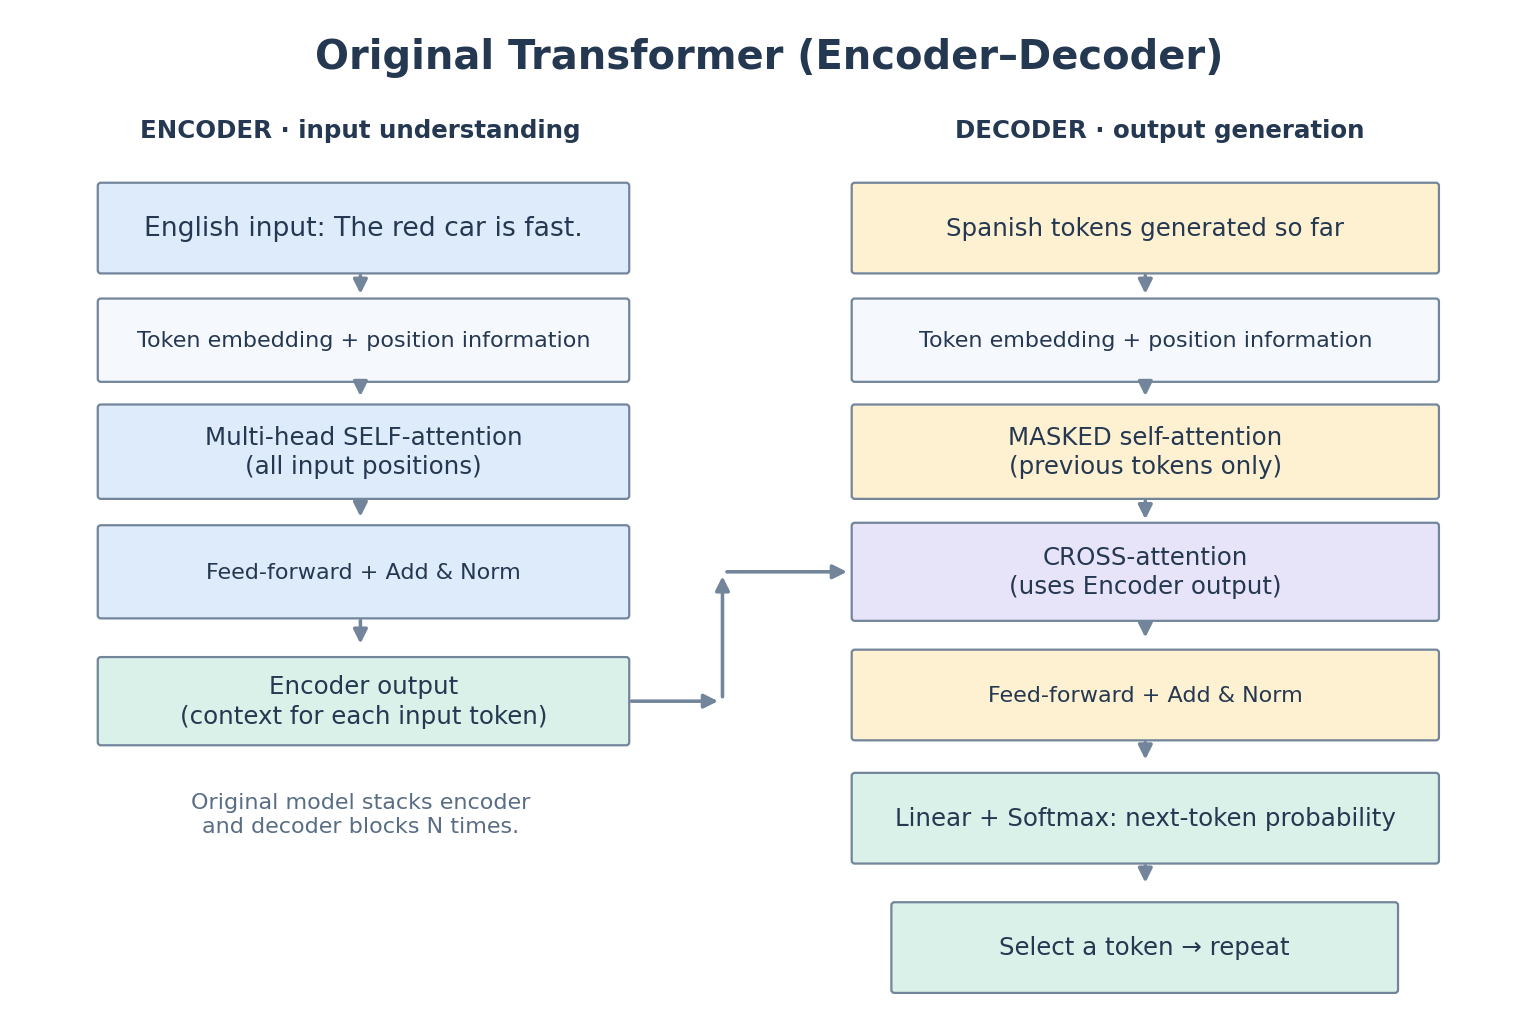

*그림: 원래 Transformer의 주요 블록과 연결을 학부 수준으로 단순화하여 새로 작성. Add & Norm, 반복 블록, 세부 경로 일부는 간략화하였다.*


## Encoder: 입력 문장 전체를 처리한다

예: **`The unbelievable red car is fast.`**

Encoder의 핵심 흐름:

1. 영어 문장을 토큰화하고 임베딩·위치 정보를 더한다.
2. **Self-Attention**으로 각 토큰이 다른 입력 토큰을 참고한다. 원래 Encoder의 Self-Attention은 입력 문장 앞뒤를 모두 참고할 수 있다.
3. Feed-Forward 등 추가 연산을 거쳐 **토큰별 문맥 표현**을 출력한다.

중요: Encoder는 문장을 **하나의 단어**나 **하나의 정수**로 바꾸는 것이 아니다. 여러 입력 토큰 각각에 대해 문맥이 반영된 벡터를 출력한다.

**핵심 질문:** Encoder의 목적은 영어 문장의 단어 순서를 스페인어 순서로 바로 바꾸는 것일까? → 아니다. 스페인어 생성을 돕는 입력 표현을 제공하는 것이다.


## Decoder: 앞서 생성한 단어와 입력 문장을 참고한다

Decoder에는 서로 다른 Attention이 두 번 등장한다.

| Decoder 단계 | 참고하는 정보 | 왜 필요한가? |
|---|---|---|
| **Masked Self-Attention** | 이미 생성된 스페인어 토큰들 | 미래에 아직 생성하지 않은 정답을 미리 보지 않기 위해 |
| **Cross-Attention** | Encoder가 만든 영어 문장의 표현 | 어떤 영어 내용을 번역하고 있는지 참고하기 위해 |
| 출력층 | Decoder가 계산한 표현 | 다음 스페인어 토큰의 확률 계산 |

원래 Transformer의 Decoder에는 이 두 Attention 외에도 Feed-Forward, 잔차 연결, 정규화가 포함된다. 지금은 **두 종류의 Attention이 무엇을 참고하는지**가 가장 중요하다.

### 왜 Causal Mask가 필요할까?

스페인어 단어를 왼쪽부터 하나씩 만든다면, 아직 생성하지 않은 오른쪽 단어를 미리 읽을 수 없어야 한다.

| 예측하려는 위치 | 볼 수 있는 출력 쪽 토큰의 예 | 아직 볼 수 없는 토큰 |
|---|---|---|
| 첫 토큰 | `[start]` | 모든 미래 스페인어 토큰 |
| 둘째 토큰 | `[start] El` | 그 뒤의 스페인어 토큰 |
| 셋째 토큰 | `[start] El coche` | 그 뒤의 스페인어 토큰 |

이때도 Decoder는 **Cross-Attention으로 영어 입력 전체를 참고**할 수 있다.


## 영어 → 스페인어 번역 예제

입력: **`The unbelievable red car is fast.`**

가능한 번역: **`El increíble coche rojo es rápido.`**

영어의 `red car`와 스페인어의 `coche rojo`는 단어 순서가 다르다. **영어와 스페인어를 같은 위치끼리 단순 대조하는 방식으로 번역하지 않는다.**

1. Encoder가 영어 문장 전체를 처리한다.
2. Decoder가 `[start]`에서 시작하여 다음 스페인어 토큰을 예측한다.
3. 선택한 토큰을 출력 쪽에 붙이고, 다음 토큰을 계속 예측한다.
4. 종료 토큰이 나오면 번역이 끝난다.

예를 들어:

```text
Encoder 입력: The unbelievable red car is fast.
Decoder 입력: [start]             → 다음 토큰: El
Decoder 입력: [start] El          → 다음 토큰: increíble
Decoder 입력: [start] El increíble → 다음 토큰: coche
Decoder 입력: [start] El increíble coche → 다음 토큰: rojo
...                               → 마지막 종료 토큰
```

여기서는 이해를 돕기 위해 출력 단위를 **단어처럼 표시**했다. 실제 Decoder는 모델의 토크나이저가 정의한 **토큰**(서브워드 포함)을 생성한다.

여기에서 `[start]`는 **설명용 표시**이며, 실제 사전훈련 모델의 시작·종료 토큰은 모델마다 다르다.

**주의:** 번역에는 여러 가지 자연스러운 표현이 존재한다. 모델이 생성한 문장을 유일한 정답으로 보지 않는다.


### '모델 훈련'과 '모델 사용'을 구분하자

이번 Lab에서는 번역 모델을 처음부터 훈련하지 않는다.

- **훈련:** 영어·스페인어 문장쌍을 이용하여 모델의 가중치를 조정하는 과정
- **사용(추론):** 이미 훈련된 모델에 **새로운 영어 문장**을 넣어 스페인어 번역을 생성하는 과정

원래 Transformer가 Encoder–Decoder 구조였다는 사실과, 실제 실습 모델이 **사전훈련된 Encoder–Decoder 계열**이라는 점을 연결하는 데 초점을 둔다.


## 원래 Transformer에서 LLM으로: 무엇이 달라졌을까?

앞에서는 **Encoder가 입력 문장을 처리하고, Decoder가 번역문을 생성하는 원래 Transformer**를 살펴보았다. 그런데 ChatGPT와 같은 생성형 언어 모델은 왜 별도의 Encoder 없이도 질문에 답하고 글을 쓸 수 있을까?

핵심은 **신경망의 구조**(아키텍처)와 **그 구조를 실제 데이터로 학습한 모델**을 구분하는 것이다.

- **Transformer:** Attention을 이용해 토큰 정보를 처리하는 *신경망 설계 방식*이다. 2017년에 제안된 원래 형태는 Encoder와 Decoder를 함께 사용했다.
- **Decoder-only Transformer:** 원래 구조에서 별도의 Encoder 및 Encoder와 연결하는 Cross-Attention 없이, 주로 **Causal Self-Attention**으로 앞선 토큰을 참고하며 다음 토큰을 예측하도록 만든 구조다. GPT 계열이 대표적이다.
- **LLM(Large Language Model):** 대규모 텍스트·코드 등의 데이터로 학습한 언어 모델을 말한다. 현대의 많은 생성형 LLM은 Decoder-only Transformer 기반이지만, **모든 LLM이 Decoder-only인 것은 아니다.**

### 모델이 문장을 생성할 수 있게 되는 과정

```text
Decoder-only Transformer 구조
       ↓
대규모 텍스트로 사전훈련(Pretraining)
: 앞선 토큰들을 보고 다음 토큰을 맞히도록 학습
       ↓
사전훈련된 언어 모델
       ↓
(선택적으로) 질문·답변 등의 예제로 추가 학습
       ↓
프롬프트를 받아 이어쓰기·질의응답 수행
```

예를 들어 `The capital of Spain is`라는 문장이 주어지면, 모델은 다음 토큰 후보들에 확률을 부여한다. 하나를 선택해 입력 뒤에 붙이고 **다음 토큰 예측을 반복**하면 문장이 생성된다. 이러한 원리는 번역 Decoder에서도 사용했지만, Decoder-only 모델에서는 **영어 입력을 처리하는 별도의 Encoder가 필요하지 않다.**

**기억할 점:** 다음 토큰 예측은 사전훈련의 주요 학습 목표이자 텍스트 생성의 핵심 원리다. 그러나 다음 토큰을 잘 예측하는 것과 **사실에 맞고 사용자의 지시를 잘 따르는 것**은 동일하지 않다. 지시문을 따르는 모델에는 추가 학습이 활용될 수 있으며, 이번 P4에서는 **학습 과정 자체를 구현하지 않고 사전훈련된 모델을 사용**한다.


## Transformer의 세 구조는 오늘날 어디에 사용할까?

원래 Transformer의 **Encoder와 Decoder를 함께 쓰는 방식** 외에도, 목적에 따라 한쪽만 사용하는 모델이 발전했다.

| 구조 | 대표 모델 | 현재의 주요 활용 | 학생들이 기억할 점 |
|---|---|---|---|
| **Encoder-only** | BERT, Sentence-BERT 계열 | 감성분석, 문서 분류, **의미 기반 검색** | 입력 텍스트를 분석하고 의미를 벡터로 표현한다. |
| **Encoder–Decoder** | MarianMT, T5, BART, Whisper | **번역**, 문서 요약, 음성 인식 | 입력을 처리한 뒤 다른 시퀀스를 생성한다. |
| **Decoder-only** | GPT, Llama 계열 | **텍스트 생성**, 질의응답, 코드 작성 | 프롬프트 뒤의 다음 토큰을 반복해서 예측한다. |

**간단한 사례:** 검색창에 `강아지를 키우는 방법`을 입력하면, Encoder 계열 임베딩 모델은 문장의 *의미*를 수치 벡터로 나타내어 `반려견 돌봄 안내`처럼 표현이 다른 관련 문서도 찾는 데 활용할 수 있다. 반면 번역 모델은 `The dog is sleeping.`을 스페인어 문장으로 변환하고, Decoder-only 모델은 `Once upon a time...` 뒤의 이야기를 계속 생성한다.

> **주의:** 이는 구조별 **대표적 활용**이지 엄격한 용도 구분은 아니다. Decoder-only 모델도 번역·요약을 할 수 있고, 모든 검색용 임베딩 모델이 Encoder-only인 것도 아니다. 이 P4 Lab에서는 **번역과 텍스트 생성**을 실습하고, P4 Project에서는 **Encoder 계열의 문서 검색**을 사용한다.


## Encoder-only: 문장 임베딩과 의미 검색

Encoder-only Transformer는 입력 문장을 **양방향 Self-Attention**으로 처리하여 문맥을 반영한 표현을 계산한다. BERT와 같은 인코더를 기반으로 만든 **문장 임베딩 모델**은 문장 전체를 하나의 벡터로 표현할 수 있다. (*BERT 자체의 모든 출력이 자동으로 문장 임베딩이 되는 것은 아니며, 문장 유사도에 적합하게 학습·구성된 모델을 사용한다.*)

예를 들어 `야생동물을 같은 개체로 중복 계산하지 않으려면?`이라는 질문을 받았다고 하자.

- 문서 A: `카메라에 같은 동물이 반복 등장하면 관측 횟수와 개체 수를 구분해야 한다.`
- 문서 B: `카메라 배터리는 매주 점검한다.`

문서 A에 질문과 **완전히 같은 단어가 없어도**, 의미가 비슷하면 검색 결과의 상위에 나타날 수 있다.

```text
질문 ------------------→ 문장 임베딩 모델 → 질문 벡터
문서 A, B, ... --------→ 문장 임베딩 모델 → 문서 벡터들
                                           ↓
                                  벡터의 유사도 비교
                                           ↓
                                  관련 문서 상위 3개
```

- **토큰 임베딩:** 한 토큰을 숫자 벡터로 나타낸다.
- **문장 임베딩:** 문장 또는 짧은 문서를 대표하는 하나의 숫자 벡터로 나타낸다.
- **의미 검색:** 질문 벡터와 문서 벡터의 유사도를 비교해 관련 문서를 찾는다. 흔히 **코사인 유사도**를 사용하지만, 이번에는 복잡한 수학적 계산 대신 *의미가 가까운 벡터를 찾는다*는 원리만 이해한다.

**주의:** 유사도가 높다는 것은 내용이 관련 있을 가능성이 높다는 뜻이지, **문서가 사실이라는 뜻은 아니다.**

## 두 구조의 협력: RAG(검색 증강 생성)

의미 검색만으로는 문서를 찾아 보여줄 수 있지만, 질문에 대한 **완성된 문장 형태의 답변**을 작성하지는 않는다. 반대로 Decoder-only 언어 모델에 질문만 넣으면 관련 문서를 확인하지 않고 답변을 생성할 수 있다.

**RAG**(Retrieval-Augmented Generation, 검색 증강 생성)는 이 두 과정을 연결한다.

```text
사용자 질문: "중복 관측 문제는 어떻게 해결하나요?"
                  ↓
① Encoder-only 기반 임베딩 모델
   → 질문과 관련된 문서 25개 중 상위 3개 검색
                  ↓
② 검색된 문서 3개 + 사용자 질문
   → Decoder-only 언어 모델에 함께 입력
                  ↓
③ 문서 내용에 근거한 답변 생성
   → 실제 근거와 일치하는지는 사람이 확인
```

| 단계 | 핵심 기능 | P4에서 사용하는 곳 |
|---|---|---|
| Encoder–Decoder | 입력 시퀀스를 다른 시퀀스로 변환 | **Lab:** 영어→스페인어 번역 |
| Encoder-only | 질문·문서를 벡터로 바꾸어 관련 문서 검색 | **Project:** 의미 검색 |
| Decoder-only | 검색된 문서를 참고하여 다음 토큰을 반복 생성 | **Project:** 답변 생성 |

**P4 Project 연결:** 사전에 준비한 **가상 '한솔 생태관측소' 안내 문서 25개**를 사용한다. 학생들은 *단어 일치 검색과 의미 검색*을 비교하고, 검색된 문서를 근거로 생성한 답변에 **문서에 없는 주장이 들어 있는지** 점검한다.

이 과정은 **모델을 새로 학습하지 않고**, 이미 학습된 모델 두 개를 연결해서 사용한다. RAG는 잘못된 답변을 줄이는 데 도움이 될 수 있지만 **항상 정확한 답을 보장하지는 않는다.**

---
# Decoder-only: Encoder 없이도 문장을 생성할까?

GPT 계열처럼 **Decoder만 여러 층 쌓은 모델**을 Decoder-only라고 한다. 영어 원문과 출력 언어를 각각 다른 구성 요소로 분리하지 않고, **모든 입력을 하나의 토큰 시퀀스**(프롬프트)로 처리한다.

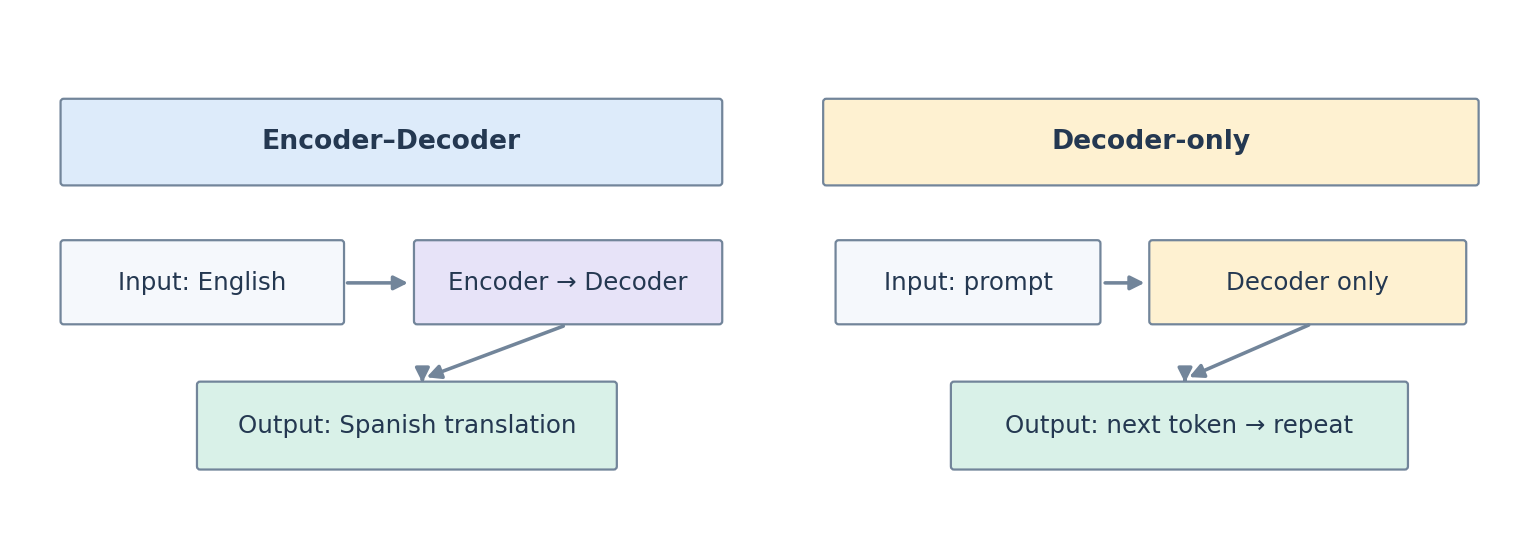

> 주의: Decoder-only의 블록은 원래 Encoder–Decoder의 Decoder를 그대로 복사한 것이 아니다. **Encoder와 연결되는 Cross-Attention은 없고**, 주로 Causal Self-Attention을 사용한다.


## 다음 토큰의 확률분포

예를 들어 모델에 다음과 같이 입력한다.

**`The capital of France is`**

모델은 가능한 다음 **토큰** 각각에 확률을 부여한다.

| 후보 토큰 | 예시 확률 |
|---|---:|
| ` Paris` | 0.65 |
| ` Lyon` | 0.08 |
| ` a` | 0.07 |
| 그 밖의 토큰 | 0.20 |

위 확률은 **설명을 위한 가상 값**이다. 실제 확률은 사전훈련된 작은 모델에서 확인한다.

선택된 다음 토큰을 입력 뒤에 붙여 같은 과정을 반복하면 문장이 길어진다.

```text
The capital of France is
The capital of France is Paris
The capital of France is Paris.
```

이것을 **자기회귀적 생성**(Autoregressive Generation)이라고 한다. 원래 Transformer의 Decoder가 다음 스페인어 토큰을 예측하는 과정과 공통된 원리다.


## Decoder-only의 간단한 활용 두 가지

**활용 ① 텍스트 이어쓰기**

- 입력: `Continue this story: A small dog opened the door...`
- 출력: 주어진 문맥에 이어지는 새로운 문장
- 관찰: 프롬프트가 달라지면 출력도 달라진다.

**활용 ② 간단한 질의응답**

- 입력: `What is the capital of Spain?`
- 출력: 모델이 생성한 답변 텍스트
- 관찰: '답'도 별도의 정답 조회 버튼이 아니라 **다음 토큰 생성을 반복한 결과**다.

둘 다 같은 Decoder-only 생성 원리를 이용한다. 다만 **작은 교육용 모델은 틀리거나 부자연스러운 답변을 생성할 수 있다.**


## 전체 구조를 한 번에 비교

| 구분 | 원래 Transformer Encoder | 원래 Transformer Decoder | Decoder-only 모델 |
|---|---|---|---|
| 주요 역할 | 입력 문장 처리 | 출력 문장 생성 | 프롬프트를 바탕으로 다음 토큰 생성 |
| Self-Attention | 입력 문장 전체 참고 | 이전 출력 토큰만 참고 | 이전 입력·생성 토큰만 참고 |
| Cross-Attention | 없음 | **Encoder 출력 참고** | **없음** |
| 대표 활용 | 번역 모델의 입력 처리 | 번역 모델의 출력 생성 | 이어쓰기, 질의응답 등 |

**정리:** Decoder-only 모델 역시 번역을 수행할 수 있다. 여기서는 **구조의 차이를 명확히 보여주기 위해** Encoder–Decoder는 영어→스페인어 번역으로, Decoder-only는 이어쓰기·질의응답으로 예를 든다.


---
# 학습 내용 확인

1. `token`과 `token ID`는 어떤 차이가 있을까? 임베딩은 왜 필요한가?
2. Q, K, V의 역할을 책 검색에 비유해 설명해 보자.
3. 원래 Transformer의 Encoder 출력은 Decoder의 어느 단계에서 사용되는가?
4. Decoder의 **Masked Self-Attention**과 **Cross-Attention**은 무엇을 다르게 참고하는가?
5. Encoder–Decoder와 Decoder-only의 가장 중요한 구조적 차이는 무엇인가?
6. 작은 언어 모델의 답변이 자연스럽지 않더라도 다음 토큰 생성 원리를 관찰할 수 있는가?
7. **Transformer 구조**와 **사전훈련된 LLM**은 무엇이 다른가?
8. 문장 임베딩 모델은 표현이 다른 질문과 문서를 어떻게 연결하는가?
9. RAG에서는 검색과 답변 생성 중 무엇을 Encoder 계열과 Decoder-only가 각각 담당하는가?

**다음:** `P4_lab_transformer_llm_clean_headings.ipynb`에서 토큰·Attention·번역·생성을 관찰한 뒤, `P4_project_document_search_RAG.ipynb`에서 실제 검색과 근거 기반 답변 생성을 실험한다.

### 참고 자료

- Vaswani et al. (2017), *Attention Is All You Need*
- [Helsinki-NLP 영어→스페인어 번역 모델](https://huggingface.co/Helsinki-NLP/opus-mt-en-es)
- [SmolLM2-135M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct)
